# Building with LangGraph

### Building a chatbot

In [1]:
pip install --upgrade -q openai langchain langchain-openai langchain-community langgraph

Note: you may need to restart the kernel to use updated packages.


In [13]:
from langgraph.graph import StateGraph
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI

import os
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)


class State(TypedDict):
    messages: Annotated[list, add_messages]


llm = ChatOpenAI(
    model="gpt-4o",
    temperature=1
)


def chatbot(state: State):
    return {
        "messages": [llm.invoke(state["messages"])]
    }


graph_builder = StateGraph(State)

graph_builder.add_node("chatbot", chatbot)

graph_builder.set_entry_point("chatbot")
graph_builder.set_finish_point("chatbot")

graph = graph_builder.compile()




# visualizing the graph

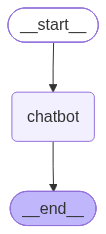

In [14]:
from IPython.display  import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [5]:
pip install grandalf -q 

Note: you may need to restart the kernel to use updated packages.


In [6]:
print(graph.get_graph().draw_ascii())

+-----------+  
| __start__ |  
+-----------+  
      *        
      *        
      *        
 +---------+   
 | chatbot |   
 +---------+   
      *        
      *        
      *        
 +---------+   
 | __end__ |   
 +---------+   


In [16]:
while True:
    user_input = input("User: ")

    if user_input.lower() in ["quite", "exit", "bye", "q"]:
        print("Goodbye")
        break

    for event in graph.stream(
        {"messages": [("user", user_input)]}
    ):
       
        for value in event.values():
            print(f"Assistant: {value['messages'][-1].content}")
            

User:  disctant to moon km


Assistant: The average distance from Earth to the Moon is about 384,400 kilometers (approximately 238,855 miles). However, this distance can vary slightly due to the Moon's elliptical orbit around Earth, ranging from about 363,300 km (225,623 miles) at its closest (perigee) to about 405,500 km (251,966 miles) at its farthest (apogee).


User:  q


Goodbye


# Tavily AI

In [17]:
pip install -q tavily

Note: you may need to restart the kernel to use updated packages.


In [24]:
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)

True

In [25]:
from tavily import TavilyClient
import os

client=TavilyClient(api_key=os.environ.get('TAVILY_API_KEY'))
response= client.search(query='What is Bitcoin')
response

{'query': 'What is Bitcoin',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://en.wikipedia.org/wiki/Bitcoin',
   'title': 'Bitcoin - Wikipedia',
   'content': 'Bitcoin (abbreviation: BTC; sign: ₿) is the first decentralized cryptocurrency. Based on a free-market ideology, bitcoin was invented in 2008 when an unknown person published a white paper under the pseudonym of Satoshi Nakamoto. Use of bitcoin as a currency began in 2009, with the release of its open-source implementation.:\u200ach. 1 From 2021 to 2025, El Salvador adopted it as legal tender currency before revoking it. As bitcoin is pseudonymous, its use by criminals has attracted the attention of [...] Bitcoin works through the collaboration of computers, each of which acts as a node "Node (networking)") in the peer-to-peer bitcoin network. Each node maintains an independent copy of a public distributed ledger of transactions, called a blockchain, without central oversight "Power (so

In [26]:
response= client.search(query='What is Bitcoin', search_deth='advanced',
                       max_result=5,
                       include_images=True,
                       include_answer=True,
                       include_raw_contect=True)
response

{'query': 'What is Bitcoin',
 'follow_up_questions': None,
 'answer': 'Bitcoin is the first decentralized cryptocurrency, invented in 2008 by an unknown person or team under the pseudonym Satoshi Nakamoto. It operates without a central authority, managed by a network of computers that verify transactions on a public digital ledger called a blockchain. Unlike traditional currencies, bitcoin is not issued or controlled by any government or central bank, allowing for peer-to-peer transactions over the internet without intermediaries. Bitcoin is digital only, existing entirely online, and has a fixed supply, which contributes to its perceived scarcity. It can be used for international remittance, as an investment, or as a tradable instrument.',
 'images': ['https://bisonapp.com/wp-content/uploads/2026/02/EN-Was-ist-Bitcoin-2.png',
  'https://a.c-dn.net/c/content/dam/publicsites/igcom/uk/images/news-article-image-folder/bg%20bitcoin%20cryptocurrency%2045345435.png/jcr:content/renditions/ori

In [27]:
answer=client.qna_search(query='what is indian team?')
answer

"The Indian cricket team is governed by the Board of Control for Cricket in India (BCCI), which represents India at the International Cricket Council (ICC). The team's selection committee, as of July 4, 2023, includes Ajit Agarkar as the chief selector and Shiv Sunder Das, Subroto Banerjee, Salil Ankola, and Sridharan Sharath as members. The India A cricket team, a developmental team representing second-tier players, is coached by Hrishikesh Kanitkar and includes players like Shreyas Iyer and Ruturaj Gaikwad. The India national football team, known as the Blue Tigers since 2013, has a history of competing in the Asian Games, winning gold in 1951 and 1962."

In [29]:
pip install -U tavily-python

Note: you may need to restart the kernel to use updated packages.


In [30]:
from tavily import TavilyClient
from langchain_openai import ChatOpenAI

client = TavilyClient()

query = 'What is the "Reflection & Critique" pattern used in agentic applications and LangGraph?'

response = client.search(
    query,
    max_results=5,
    search_depth="advanced"
)["results"]

response

[{'url': 'https://medium.com/aimonks/reflection-agents-with-langgraph-agentic-llm-based-applications-87e43c27adc7',
  'title': 'Reflection Agents With LangGraph | Agentic LLM Based Applications | by Prince Krampah | 𝐀𝐈 𝐦𝐨𝐧𝐤𝐬.𝐢𝐨 | Medium',
  'content': '## What Is Reflection?\n\nReflection is a prompting strategy used to improve the quality and success rate of agents and similar AI systems. It involves prompting an LLM to reflect on and critique its past actions, sometimes incorporating additional external information such as tools and observations.\n\nImagine an LLM based application like ChatGPT. If you ask it to write you code. It immediately begins to spit out content of the code. Do you know any programmer that just writes code that fast and never tests it, but pushes it into production? Forget about other programmers, just maybe they are that intelligent. Can you personally do that? Of course not, highly unlikely. [...] Code With Prince\n\nThe generator will do the generative part

In [33]:
from langchain_openai import ChatOpenAI

prompt = [
    {
        "role": "system",
        "content": """You are an AI critical thinker research assistant.
Your sole purpose is to write well written, objective and structured reports on given text."""
    },
    {
        "role": "user",
        "content": f"""Information: "{response}"

Using the above information, answer the following query: "{query}" in a detailed report"""
    }
]

llm = ChatOpenAI(
    model="gpt-4o",
    temperature=1
)

result = llm.invoke(prompt)

print(result.content)

## Report on "Reflection & Critique" Pattern in Agentic Applications and LangGraph

### Introduction
The "Reflection & Critique" pattern is a sophisticated approach used in agentic applications, particularly those involving language models, such as LangGraph. This technique is designed to enhance the quality and effectiveness of AI outputs by introducing a systematic process for self-evaluation and improvement. The following report delves into the critical aspects of this pattern, its implementation in LangGraph, and its advantages in developing AI systems.

### Understanding Reflection in AI
Reflection in AI involves prompting a language model (LLM) to analyze and critique its previous actions. This process not only helps identify errors but also incorporates external information and tools to refine subsequent outputs. For instance, an AI like ChatGPT, when tasked with generating code, might employ reflection to ensure the code's quality before finalization, much like a human programm

# ehancing the chatbot with tools

In [37]:
pip install -U langchain-tavily

Note: you may need to restart the kernel to use updated packages.


In [38]:

import os
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_tavily import TavilySearch
tool = TavilySearch(max_results=3)

tools = [tool]

In [39]:
response=tool.invoke('what is gpt code')
response

{'query': 'what is gpt code',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://cloud.google.com/discover/what-is-gpt',
   'title': 'What is GPT and how does it work? | Google Cloud',
   'content': "GPT, or a generative pre-trained transformer, is a type of large language model (LLM) that utilizes deep learning to produce human-like text. Neural networks are trained on massive datasets containing text and code, enabling them to understand and generate coherent and contextually relevant responses. As a key component in the field of generative AI, GPT pushes the boundaries of what's possible with AI, enabling machines to produce creative and human-quality content. [...] GPT technology has the potential to revolutionize the way developers work. It can be used to assist in computer code generation, which can be a valuable tool for developers who are looking to automate tasks or speed up the development process.\n\nThis can free up developers to foc

In [46]:
from langgraph.graph import StateGraph
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
from langgraph.prebuilt import ToolNode, tools_condition

import os
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)


class State(TypedDict):
    messages: Annotated[list, add_messages]

tool = TavilySearch(max_results=3)
tools = [tool]

llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.5
)
llm_with_tools=llm.bind_tools(tools)


def chatbot(state: State):
    return {
        "messages": [llm.invoke(state["messages"])]
    }


graph_builder = StateGraph(State)

graph_builder.add_node("chatbot", chatbot)
tool_node=ToolNode(tools=tools)
graph_builder.add_node('tools',tool_node)

graph_builder.add_conditional_edges(
    'chatbot',
    tools_condition,
)

graph_builder.add_edge('tools','chatbot')

graph_builder.set_entry_point("chatbot")
graph_builder.set_finish_point("chatbot")

graph = graph_builder.compile()

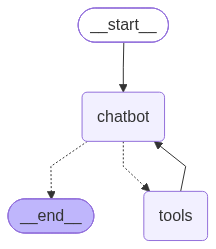

In [47]:
from IPython.display  import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [48]:
while True:
    user_input = input("User: ")

    if user_input.lower() in ["quite", "exit", "bye", "q"]:
        print("Goodbye")
        break

    for event in graph.stream(
        {"messages": [("user", user_input)]}
    ):
       
        for value in event.values():
            print(f"Assistant: {value['messages'][-1].content}")
            

User:  what is today special?


Assistant: Today is October 4, 2023. Depending on where you are, there may be various events or observances taking place. For instance, October 4 is recognized as World Animal Day, a day dedicated to raising awareness about animal welfare. Additionally, there may be local events, holidays, or celebrations specific to your region. If you're looking for something specific, let me know!


User:  q


Goodbye


# addind Memory to the chatbot

In [49]:
pip install -U langgraph langchain langchain-openai langchain-community

Note: you may need to restart the kernel to use updated packages.


In [51]:
pip install -U langgraph-checkpoint-sqlite


   ------------- -------------------------- 1/3 [aiosqlite]
   -------------------------- ------------- 2/3 [langgraph-checkpoint-sqlite]
   ---------------------------------------- 3/3 [langgraph-checkpoint-sqlite]

Note: you may need to restart the kernel to use updated packages.


In [52]:
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.checkpoint.memory import MemorySaver

memory = SqliteSaver.from_conn_string(":memory:")

graph = graph_builder.compile(
    checkpointer=MemorySaver()
)

In [53]:
config = {"configurable": {"thread_id": 1}}

prompt = "Hi! My name is Andrei and you are a math tutor."

events = graph.stream(
    {"messages": [("user", prompt)]},
    config,
    stream_mode="values"
)

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Hi! My name is Andrei and you are a math tutor.
================================== Ai Message ==================================

Hi Andrei! I'm glad to be your math tutor. What specific topics or questions do you need help with today?
